# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**

- **Устройство:** Kaggle, одна GPU Tesla T4 (`CUDA_VISIBLE_DEVICES=0`), Python 3.13, torch 2.11.0+cu130, transformers 5.22.1, datasets 5.1.0
- **Модель:** [cointegrated/rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2), лицензия MIT, revision `a53f0afc4b34c94012191a043c52e2271fa23f27`
- **Датасет:** [RCC-MSU/collection3](https://huggingface.co/datasets/RCC-MSU/collection3), в карточке лицензия указана как `other`
- **Бонусы:** 6.1 (63 предложения, файл `artifacts/extra_ner.jsonl`), 6.2 (`FacebookAI/xlm-roberta-base`, revision `e73636d4f797dec63c3081bb6ed5c7b0bb3f2089`, лицензия MIT по карточке), 6.3, 6.4, 6.5
- **Источники:** документация transformers, datasets, seqeval, PyTorch (экспорт в ONNX) и ONNX Runtime, карточки модели и датасета на Hugging Face, материалы курса
- **Нерешённые задачи:** нет
- **Примечание:** ноутбук прогнан целиком с `FAST_MODE = False`. В 6.4 при экспорте в ONNX появляются предупреждения старого экспортёра (красный вывод), на результат они не повлияли

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.11.0+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [4]:
FAST_MODE = False  # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.1', '6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'   # id модели на Hugging Face Hub
REVISION = 'a53f0afc4b34c94012191a043c52e2271fa23f27'   # полный commit hash (40 символов)
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: a53f0afc4b34c94012191a043c52e2271fa23f27
license:  mit
language: ['ru']
updated:  2022-06-30 14:26:53+00:00
weights:  {'pytorch_model.bin': '112 MB'}


config.json:   0%|          | 0.00/715 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:**

Я взяла `cointegrated/rubert-tiny2`: это маленький BERT (3 слоя, hidden 312, 29,1 млн параметров), обученный только на русском языке, а мой датасет тоже русский (новости). Словарь на 83 828 токенов подходит под русскую морфологию, лицензия MIT, веса около 112 МБ, поэтому на T4 эксперименты занимают секунды и минуты. В карточке метрик по NER нет, так что качество оцениваю только по своим запускам. От такой маленькой модели я ожидала F1 ниже, чем у base-моделей.

Сравнение с альтернативами:

| модель | параметров | языки | комментарий |
|---|---|---|---|
| `rubert-tiny2` (выбрана) | 29 млн | русский | быстрая, хватает T4 за секунды |
| `DeepPavlov/rubert-base-cased` | около 180 млн | русский | должна быть точнее, но примерно в 6 раз больше и медленнее |
| `FacebookAI/xlm-roberta-base` | около 280 млн | около 100 языков | для одноязычной задачи размер избыточен, её я взяла в бонусе 6.2 |

Если не фиксировать `revision`, владелец репозитория может перезалить веса, токенизатор или конфиг, и `main` начнёт указывать на другую версию. Тогда через полгода словарь, разбиение на сабворды или веса могут отличаться, и числа из ноутбука не воспроизведутся. Если поменяется формат файлов, модель может и вовсе не загрузиться.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  118MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    def count(module):
        return sum(p.numel() for p in module.parameters())

    base = model.base_model
    layer_list = next(m for name, m in base.named_modules()
                      if name.split('.')[-1] == 'layer' and isinstance(m, torch.nn.ModuleList))
    layers = [count(layer) for layer in layer_list]
    embeddings, head = count(base.embeddings), count(model.classifier)
    encoder = sum(layers)
    return dict(embeddings=embeddings, encoder=encoder, head=head,
                other=count(model) - embeddings - encoder - head, layers=layers)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

print('words per sentence:', [len(words) for words in demo_texts])
print('input_ids     ', tuple(enc['input_ids'].shape))
print('attention_mask', tuple(enc['attention_mask'].shape))
for i, hidden in enumerate(out.hidden_states):
    print(f'hidden_states[{i}]', tuple(hidden.shape))
print('logits        ', tuple(out.logits.shape))
for i in range(len(demo_texts)):
    print(enc.tokens(i))

words per sentence: [6, 6]
input_ids      (2, 11)
attention_mask (2, 11)
hidden_states[0] (2, 11, 312)
hidden_states[1] (2, 11, 312)
hidden_states[2] (2, 11, 312)
hidden_states[3] (2, 11, 312)
logits         (2, 11, 7)
['[CLS]', 'Петр', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке', '.', '[SEP]']
['[CLS]', 'IT', '##M', '##O', 'University', 'is', 'in', 'Saint', 'Petersburg', '[SEP]', '[PAD]']


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 6.5 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:**

Слова проходят токенизатор и превращаются в сабворды. Дальше форма тензора меняется так:

| этап | форма |
|---|---|
| `input_ids`, `attention_mask` | (2, 11) |
| `hidden_states[0]` (после эмбеддингов) | (2, 11, 312) |
| `hidden_states[1..3]` (после каждого из 3 слоёв энкодера) | (2, 11, 312) |
| `logits` (dropout и Linear 312 → 7) | (2, 11, 7) |

Параметры по блокам:

| блок | параметров | доля |
|---|---|---|
| эмбеддинги | 26 794 560 | 92,1% |
| энкодер (3 слоя по 767 184) | 2 301 552 | 7,9% |
| голова | 2 191 | 0,0% |
| всего | 29 098 303 | 100% |

Больше всего параметров в эмбеддингах, потому что одна таблица токенов 83 828 × 312 занимает около 26,2 млн. Вычислений в этом блоке почти нет, это просто выборка строк.

Токены обмениваются информацией только в слоях энкодера. Эмбеддинги и линейная голова обрабатывают каждый токен независимо.

`T = 11` при шести словах в каждом предложении по двум причинам. Слова режутся на сабворды (Чайковский → `Чайк`, `##овский`; Воткинске → `Вот`, `##кинс`, `##ке`; ITMO → `IT`, `##M`, `##O`) и добавляются `[CLS]` и `[SEP]`. Кроме того, второе предложение дополнено `[PAD]` до длины первого.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None 
raw = load_dataset(DATASET_ID, revision='refs/convert/parquet')      
raw = DatasetDict({split: raw[split] for split in ['train', 'validation', 'test']})

tag_feature = raw['train'].features['ner_tags'].feature
if hasattr(tag_feature, 'names'):
    LABEL_NAMES = list(tag_feature.names)
else:
    LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
assert LABEL_NAMES == ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC'], LABEL_NAMES

print(raw)
print(LABEL_NAMES)
print(raw['train'][0])

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/245k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/219k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
{'id': '0', 'tokens': ['Дополнение', ':', 'Д', '.', 'Медведев', 'присвоил', 'звания', 'сотрудников', 'полиции', 'и', 'переназначил', '14', 'руководителей', 'УВД', ',', 'ГУВД', 'и', 'МВД', 'по', 'субъектам', 'РФ', '.'], 'ner_tags': [0, 0, 1, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 3, 0, 3, 0, 0, 5, 0]}


тип             train   validation         test        всего
LOC             4,881        1,168        1,175        7,224
ORG             5,960        1,308        1,256        8,524
PER             7,406        1,641        1,570       10,617
все            18,247        4,117        4,001       26,365

длина спанов в словах (train)
тип        спанов  среднее  медиана   max  1 слово
LOC         4,881     1.32        1     8    77.6%
ORG         5,960     2.00        1    18    53.8%
PER         7,406     2.01        2    10    27.4%

длина предложений в словах
train      предложений  9,301  среднее  20.2  медиана  18  p95   41  max  256  без сущностей  19.5%
validation предложений  2,153  среднее  20.4  медиана  18  p95   41  max  118  без сущностей  23.4%
test       предложений  1,922  среднее  20.9  медиана  19  p95   42  max  122  без сущностей  18.3%

доля слов с тегом O в train: 82.3% (187,656 слов)


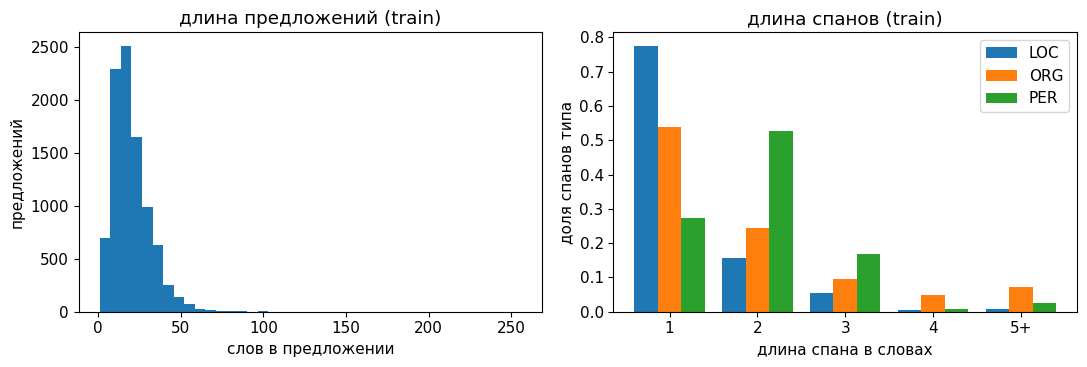

In [14]:
from seqeval.metrics.sequence_labeling import get_entities

entity_types = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
split_names = list(raw)
split_spans = {split: [get_entities([LABEL_NAMES[i] for i in tags]) for tags in raw[split]['ner_tags']]
               for split in split_names}

entity_counts = {split: collections.Counter(kind for sent in spans for kind, _, _ in sent)
                 for split, spans in split_spans.items()}
print(f'{"тип":<8}' + ''.join(f'{s:>13}' for s in split_names) + f'{"всего":>13}')
for kind in entity_types:
    row = [entity_counts[s][kind] for s in split_names]
    print(f'{kind:<8}' + ''.join(f'{v:>13,}' for v in row) + f'{sum(row):>13,}')
totals = [sum(entity_counts[s].values()) for s in split_names]
print(f'{"все":<8}' + ''.join(f'{v:>13,}' for v in totals) + f'{sum(totals):>13,}')

span_lengths = collections.defaultdict(list)
for sent in split_spans['train']:
    for kind, begin, end in sent:
        span_lengths[kind].append(end - begin + 1)
print('\nдлина спанов в словах (train)')
print(f'{"тип":<8}{"спанов":>9}{"среднее":>9}{"медиана":>9}{"max":>6}{"1 слово":>9}')
for kind in entity_types:
    lens = np.array(span_lengths[kind])
    print(f'{kind:<8}{len(lens):>9,}{lens.mean():>9.2f}{np.median(lens):>9.0f}{lens.max():>6}{(lens == 1).mean():>9.1%}')

print('\nдлина предложений в словах')
for split in split_names:
    lens = np.array([len(words) for words in raw[split]['tokens']])
    without_entities = np.mean([not sent for sent in split_spans[split]])
    print(f'{split:<11}предложений {len(lens):>6,}  среднее {lens.mean():5.1f}  медиана {np.median(lens):3.0f}  '
          f'p95 {np.percentile(lens, 95):4.0f}  max {lens.max():4d}  без сущностей {without_entities:6.1%}')

o_id = LABEL_NAMES.index('O')
n_words = sum(len(tags) for tags in raw['train']['ner_tags'])
n_outside = sum(tags.count(o_id) for tags in raw['train']['ner_tags'])
print(f'\nдоля слов с тегом O в train: {n_outside / n_words:.1%} ({n_words:,} слов)')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist([len(words) for words in raw['train']['tokens']], bins=40)
axes[0].set_xlabel('слов в предложении')
axes[0].set_ylabel('предложений')
axes[0].set_title('длина предложений (train)')

max_len = 5
width = 0.8 / len(entity_types)
for k, kind in enumerate(entity_types):
    lens = np.minimum(span_lengths[kind], max_len)
    shares = np.bincount(lens, minlength=max_len + 1)[1:] / len(lens)
    axes[1].bar(np.arange(1, max_len + 1) + k * width, shares, width, label=kind)
axes[1].set_xticks(np.arange(1, max_len + 1) + width, [str(i) if i < max_len else f'{max_len}+' for i in range(1, max_len + 1)])
axes[1].set_xlabel('длина спана в словах')
axes[1].set_ylabel('доля спанов типа')
axes[1].set_title('длина спанов (train)')
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:**

Датасет **Collection3** (`RCC-MSU/collection3` на Hugging Face, Можарова и Лукашевич, 2016): русские новостные тексты на основе коллекции Persons-1000. Разметка ручная, по правилам, близким к MUC-7, в инструменте Brat. В формат IOB2 и на train/validation/test его разбила команда DeepPavlov. В карточке лицензия указана как `other` без подробностей, поэтому использую данные только в учебных целях.

Размер по сплитам (предложений: train 9 301, validation 2 153, test 1 922) и число сущностей:

| тип | train | validation | test |
|---|---|---|---|
| LOC | 4 881 | 1 168 | 1 175 |
| ORG | 5 960 | 1 308 | 1 256 |
| PER | 7 406 | 1 641 | 1 570 |
| всего | 18 247 | 4 117 | 4 001 |

Длина спанов в словах (train):

| тип | среднее | медиана | максимум | из одного слова |
|---|---|---|---|---|
| LOC | 1,32 | 1 | 8 | 77,6% |
| ORG | 2,00 | 1 | 18 | 53,8% |
| PER | 2,01 | 2 | 10 | 27,4% |

Самый редкий тип LOC, но перекос небольшой. У ORG спаны самые разнообразные: аббревиатуры и длинные названия.

Особенности данных, которые могут повлиять на обучение:

- предложения в среднем по 20 слов, 95-й процентиль 41, но в train есть предложение на 256 слов, длиннее `MAX_LENGTH`;
- в train 19,5% предложений без сущностей, а слов с тегом `O` 82,3%, то есть фон сильно преобладает;
- разметка местами шумная (примеры в 5.1);
- дефисы и кавычки в датасете отдельные токены («пресс - службе»).

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, start, kind = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        prefix, _, tag_type = tag.partition('-')
        continues = prefix == 'I' and kind == tag_type
        if kind is not None and not continues:
            spans.append((start, i, kind))
            start, kind = None, None
        if prefix in ('B', 'I') and kind is None:
            start, kind = i, tag_type
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, kind in spans:
        if not 0 <= start < end <= n_words:
            raise ValueError(f'спан {(start, end, kind)} не помещается в {n_words} слов')
        tags[start] = f'B-{kind}'
        for i in range(start + 1, end):
            tags[i] = f'I-{kind}'
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels, prev = [], None
    for word in word_ids:
        if word is None:
            labels.append(-100)
        elif word != prev:
            labels.append(word_labels[word])
        elif b_to_i is None:
            labels.append(-100)
        else:
            labels.append(b_to_i.get(word_labels[word], word_labels[word]))
        prev = word
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)

print(f'{"сплит":<12}{"предл.":>8}{"BIO совпал":>12}{"спаны совпали":>15}{"I- без B-":>11}')
orphan_examples = []
for split in raw:
    gold_tags = [[LABEL_NAMES[i] for i in tags] for tags in raw[split]['ner_tags']]
    path = DATA_DIR / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for idx, (words, tags) in enumerate(zip(raw[split]['tokens'], gold_tags)):
            record = dict(id=idx, tokens=list(words), spans=[list(span) for span in bio_to_spans(tags)])
            f.write(json.dumps(record, ensure_ascii=False) + '\n')

    restored_tokens, restored_tags = [], []
    with path.open(encoding='utf-8') as f:
        for line in f:
            record = json.loads(line)
            restored_tokens.append(record['tokens'])
            restored_tags.append(spans_to_bio([tuple(span) for span in record['spans']], len(record['tokens'])))

    assert restored_tokens == [list(words) for words in raw[split]['tokens']]
    same_bio = sum(a == b for a, b in zip(restored_tags, gold_tags))
    same_spans = sum(bio_to_spans(a) == bio_to_spans(b) for a, b in zip(restored_tags, gold_tags))
    orphans = [i for i, (a, b) in enumerate(zip(restored_tags, gold_tags)) if a != b]
    assert same_spans == len(gold_tags), 'после круга туда-обратно спаны должны совпасть'
    print(f'{split:<12}{len(gold_tags):>8,}{same_bio:>12,}{same_spans:>15,}{len(orphans):>11,}')
    orphan_examples += [(split, i) for i in orphans[:2]]

for split, i in orphan_examples:
    words = raw[split][i]['tokens']
    tags = [LABEL_NAMES[t] for t in raw[split][i]['ner_tags']]
    print(f'\n{split}[{i}] исходные теги, где I- без B-:')
    print([(w, t) for w, t in zip(words, tags) if t != 'O'])

print()
for ex in raw['train'].select(range(5)):
    words = ex['tokens']
    spans = bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
    print(' '.join(words))
    print('   ', [(' '.join(words[b:e]), kind) for b, e, kind in spans])

сплит         предл.  BIO совпал  спаны совпали  I- без B-
train          9,301       9,296          9,301          5
validation     2,153       2,153          2,153          0
test           1,922       1,921          1,922          1

train[1751] исходные теги, где I- без B-:
[('Мособлдума', 'B-ORG'), ('Воробьева', 'B-PER'), ('о', 'I-PER'), ('Подмосковья', 'B-LOC')]

train[2524] исходные теги, где I- без B-:
[('Власть', 'I-ORG'), ('Вероника', 'B-PER'), ('Куцылло', 'I-PER')]

test[1242] исходные теги, где I- без B-:
[('Первоуральск', 'I-ORG'), ('Ольгу', 'B-PER'), ('Вертлюгову', 'I-PER')]

Дополнение : Д . Медведев присвоил звания сотрудников полиции и переназначил 14 руководителей УВД , ГУВД и МВД по субъектам РФ .
    [('Д . Медведев', 'PER'), ('УВД', 'ORG'), ('ГУВД', 'ORG'), ('МВД', 'ORG'), ('РФ', 'LOC')]
Президент России Дмитрий Медведев присвоил звания сотрудников полиции и переназначил 14 руководителей управлений , главных управлений и министерств внутренних дел по субъектам РФ и

In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

Map:   0%|          | 0/2153 [00:00<?, ? examples/s]

Map:   0%|          | 0/1922 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']
train: проверено 9288 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 434
[CLS]            None  -100
До                  0  O
##полнение          0  -100
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и             

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:**

Метка ставится на первый сабворд, потому что оценивается тег слова, а предсказание берётся по первому сабворду. У слова должна быть одна метка, а BIO-теги для продолжений слова в датасете не определены. Значение `-100` это `ignore_index` у cross-entropy: такие позиции (продолжения слов, `[CLS]`, `[SEP]`, паддинг) не входят в loss и не дают градиента.

Обрезка и потерянные слова в train:

- обрезано по `MAX_LENGTH`: 10 предложений из 9 301;
- без метки осталось 434 слова из 187 656 (0,23%): из-за обрезки или потому, что токенизатор не дал им сабвордов.

При предсказании такие слова получают `O`. Если сущность оказалась в обрезанном хвосте, она засчитывается как пропуск и немного снижает recall. Для validation и test я это отдельно не считала, но там самые длинные предложения по 118 и 122 слова, так что единичные обрезки возможны.

Что нашлось при конвертации:

- круг BIO → спаны → BIO дал совпадение спанов во всех предложениях всех сплитов;
- строки BIO не совпали в 5 предложениях train и в 1 test: там `I-` стоит без `B-` (например, «Власть» с тегом `I-ORG` в начале спана), и по принятому правилу такой тег начинает новый спан;
- вложенных и пересекающихся спанов в этой разметке нет.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: tag_counts.most_common(1)[0][0] for word, tag_counts in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tokens = [list(ws) for ws in data['train']['tokens']]
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority_tagger = fit_majority_tagger(train_tokens, train_tags)
majority_pred = [predict_majority(majority_tagger, words) for words in val_tokens]

set_seed(SEED)
random_head_model = make_model()
random_head_pred = predict_word_tags(random_head_model, val_tokens)
del random_head_model

baseline = dict(majority=entity_scores(val_gold, majority_pred),
                random_head=entity_scores(val_gold, random_head_pred))

for name, scores in baseline.items():
    print(f'{name:<12}' + '  '.join(f'{k} {v:.4f}' for k, v in scores.items()))

n_val_words = sum(len(words) for words in val_tokens)
n_unknown = sum(word not in majority_tagger for words in val_tokens for word in words)
print(f'\nсловарь бейзлайна: {len(majority_tagger):,} слов, незнакомых слов в validation {n_unknown / n_val_words:.1%}')
print('теги случайной головы:', dict(collections.Counter(tag for tags in random_head_pred for tag in tags).most_common()))

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

majority    f1_micro 0.5613  f1_macro 0.5786  precision 0.5626  recall 0.5601
random_head f1_micro 0.0381  f1_macro 0.0353  precision 0.0223  recall 0.1304

словарь бейзлайна: 27,410 слов, незнакомых слов в validation 11.2%
теги случайной головы: {'O': 11544, 'I-PER': 11459, 'B-PER': 8688, 'I-LOC': 4833, 'B-LOC': 3053, 'I-ORG': 2511, 'B-ORG': 1768}


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**

Метрики на validation:

| модель | F1 micro | precision | recall |
|---|---|---|---|
| словарный бейзлайн | 0,5613 | 0,5626 | 0,5601 |
| энкодер со случайной головой | 0,0381 | 0,0223 | 0,1304 |

**Словарный бейзлайн** работает на повторяющихся сущностях новостей (страны, министерства, известные фамилии). Ограничения у него такие:

- 11,2% слов validation нет в словаре train, и они всегда получают `O`;
- слово без контекста не отличает фамилию от названия организации;
- он не знает границ спана, поэтому многословные сущности совпадают целиком, только если угаданы все слова.

**Энкодер со случайной головой** размечает почти наугад: тегом `O` только 11 544 слова из 43 856 (26% при настоящих 82%), остальные теги раздаются почти равномерно. Энкодер предобучен, но случайная голова не знает, какой вектор соответствует какому тегу. Для засчитанного спана нужны точные границы и тип, поэтому совпадений почти нет, и F1 близок к нулю.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:
        for param in model.base_model.parameters():
            param.requires_grad = False

    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=2 * batch_size,
        weight_decay=0.01,
        warmup_steps=int(0.1 * total_steps),
        eval_strategy='steps',
        eval_steps=max(1, total_steps // 12),
        logging_strategy='steps',
        logging_steps=max(1, total_steps // 30),
        save_strategy='no',
        fp16=device.type == 'cuda',
        seed=SEED,
        report_to='none',
        disable_tqdm=True,
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok, pad_to_multiple_of=8),
                      processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start
    return trainer.state.log_history, seconds

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.407', 'grad_norm': '1.465', 'learning_rate': '6.437e-05', 'epoch': '0.09966'}
{'loss': '0.464', 'grad_norm': '0.9913', 'learning_rate': '0.000131', 'epoch': '0.1993'}
{'eval_loss': '0.1902', 'eval_runtime': '0.4875', 'eval_samples_per_second': '4416', 'eval_steps_per_second': '69.74', 'epoch': '0.2474'}
{'loss': '0.2265', 'grad_norm': '1.847', 'learning_rate': '0.0001977', 'epoch': '0.299'}
{'loss': '0.1361', 'grad_norm': '1.653', 'learning_rate': '0.0001929', 'epoch': '0.3986'}
{'eval_loss': '0.07241', 'eval_runtime': '0.4807', 'eval_samples_per_second': '4479', 'eval_steps_per_second': '70.73', 'epoch': '0.4948'}
{'loss': '0.1074', 'grad_norm': '2.484', 'learning_rate': '0.0001855', 'epoch': '0.4983'}
{'loss': '0.0973', 'grad_norm': '1.859', 'learning_rate': '0.0001781', 'epoch': '0.5979'}
{'loss': '0.0886', 'grad_norm': '0.5868', 'learning_rate': '0.0001707', 'epoch': '0.6976'}
{'eval_loss': '0.05374', 'eval_runtime': '0.4843', 'eval_samples_per_second': '4446', 'eval_st

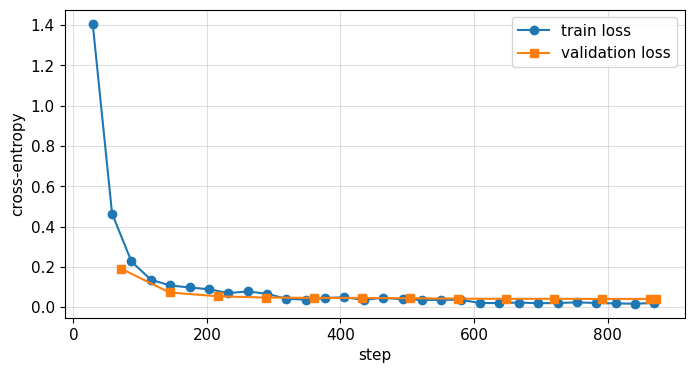

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:**

Гиперпараметры:

| параметр | значение | почему |
|---|---|---|
| learning rate | 2e-4 | для маленькой rubert-tiny2 такой порядок рекомендован, у base-моделей шаг меньше |
| batch size | 32 | помещается в память T4 |
| эпохи | 3 | |
| warmup | 10% шагов, дальше линейный спад lr | |
| weight decay | 0,01 | |
| fp16 | да | ускоряет на GPU |

Всего 873 шага, оценка на validation каждые 72 шага.

По кривым: train loss падает с 1,41 до около 0,02, validation loss с 0,190 до 0,0405 и в конце выходит на плато (0,0412 в середине третьей эпохи, 0,0405 в конце). Роста validation loss нет, то есть явного переобучения не видно, хотя разрыв между train (0,02) и validation (0,04) остаётся. Больше эпох вряд ли много даст: lr к концу уже близок к нулю, а loss на плато.

Обучение заняло **28,1 секунды** на Tesla T4 (Kaggle).

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    n_gold = n_pred = n_correct = 0
    for gold_tags, pred_tags in zip(gold, pred):
        for g, p in zip(gold_tags, pred_tags):
            n_gold += g != 'O'
            n_pred += p != 'O'
            n_correct += g != 'O' and g == p
    if n_gold + n_pred == 0:
        return 0.0
    return 2 * n_correct / (n_gold + n_pred)

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

val_pred = predict_word_tags(model, val_tokens)
test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)

for split_name, gold_tags, pred_tags in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    print(f'{split_name}:')
    print(classification_report(gold_tags, pred_tags, digits=4, zero_division=0))
    scores = entity_scores(gold_tags, pred_tags)
    print(f'F1 micro {scores["f1_micro"]:.4f}   F1 macro {scores["f1_macro"]:.4f}   '
          f'token F1 {token_f1(gold_tags, pred_tags):.4f}\n')

final = entity_scores(test_gold, test_pred)
final['token_f1'] = token_f1(test_gold, test_pred)
test_report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final['per_type'] = {kind: test_report[kind] for kind in ENTITY_TYPES if kind in test_report}
final['validation'] = dict(entity_scores(val_gold, val_pred), token_f1=token_f1(val_gold, val_pred))

validation:
              precision    recall  f1-score   support

         LOC     0.9594    0.9503    0.9548      1168
         ORG     0.8384    0.9006    0.8684      1308
         PER     0.9659    0.9835    0.9746      1641

   micro avg     0.9218    0.9478    0.9346      4117
   macro avg     0.9212    0.9448    0.9326      4117
weighted avg     0.9235    0.9478    0.9353      4117

F1 micro 0.9346   F1 macro 0.9326   token F1 0.9546

test:
              precision    recall  f1-score   support

         LOC     0.9530    0.9660    0.9594      1175
         ORG     0.8511    0.8917    0.8709      1256
         PER     0.9600    0.9796    0.9697      1570

   micro avg     0.9231    0.9480    0.9354      4001
   macro avg     0.9214    0.9458    0.9334      4001
weighted avg     0.9238    0.9480    0.9357      4001

F1 micro 0.9354   F1 macro 0.9334   token F1 0.9588



**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:**

Результаты на test:

| тип | precision | recall | F1 | support |
|---|---|---|---|---|
| LOC | 0,9530 | 0,9660 | 0,9594 | 1 175 |
| ORG | 0,8511 | 0,8917 | 0,8709 | 1 256 |
| PER | 0,9600 | 0,9796 | 0,9697 | 1 570 |
| micro | 0,9231 | 0,9480 | **0,9354** | 4 001 |

Сводка по сплитам:

| сплит | F1 micro | F1 macro | токенный F1 |
|---|---|---|---|
| validation | 0,9346 | 0,9326 | 0,9546 |
| test | 0,9354 | 0,9334 | 0,9588 |

Хуже всего распознаётся **ORG** (F1 0,8709 на test против 0,9594 у LOC и 0,9697 у PER). Организации разнообразнее: это и аббревиатуры (МВД), и длинные названия, иногда в кавычках, у них самые длинные спаны (максимум 18 слов), а границы часто неочевидны. У ORG recall (0,8917) выше precision (0,8511): модель находит почти все организации, но часто с лишними или неточными границами.

Micro F1 и macro F1 почти одинаковы (0,9354 и 0,9334): типов три, они сопоставимы по размеру, а macro чуть ниже, потому что ORG весит столько же, сколько PER.

Токенный F1 (0,9588) выше F1 по сущностям (0,9354). Он считает слова, поэтому спан с ошибкой в одной границе всё равно приносит баллы за остальные слова, а в seqeval такой спан не засчитывается совсем. Пользователю NER обычно нужны сущности целиком (для поиска, связывания, индексации), поэтому F1 по сущностям ближе к реальному качеству.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    def overlap(a, b):
        return max(0, min(a[1], b[1]) - max(a[0], b[0]))

    gold_spans = [tuple(span) for span in gold_spans]
    pred_spans = [tuple(span) for span in pred_spans]
    results = []
    for g in gold_spans:
        touching = [p for p in pred_spans if overlap(g, p) > 0]
        same_type = [p for p in touching if p[2] == g[2]]
        other_type = [p for p in touching if p[2] != g[2]]
        if g in touching:
            results.append(('correct', g, g))
        elif same_type:
            results.append(('boundary', g, max(same_type, key=lambda p: overlap(g, p))))
        elif other_type:
            results.append(('type', g, max(other_type, key=lambda p: overlap(g, p))))
        else:
            results.append(('missed', g, None))
    for p in pred_spans:
        if not any(overlap(p, g) > 0 for g in gold_spans):
            results.append(('spurious', None, p))
    return results

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

categorized = [categorize_errors(bio_to_spans(g), bio_to_spans(p)) for g, p in zip(val_gold, val_pred)]
category_counts = collections.Counter(category for res in categorized for category, _, _ in res)
errors = {category: category_counts[category] for category in ERROR_CATEGORIES}
n_errors = sum(count for category, count in errors.items() if category != 'correct')

print(f'{"категория":<11}{"число":>8}{"доля среди ошибок":>20}')
for category in ERROR_CATEGORIES:
    share = '-' if category == 'correct' else f'{errors[category] / n_errors:.1%}'
    print(f'{category:<11}{errors[category]:>8,}{share:>20}')

by_category = collections.defaultdict(list)
for idx, res in enumerate(categorized):
    for category, g, p in res:
        if category != 'correct':
            by_category[category].append((idx, g, p))

print('\nпо типам сущности:')
for category in ERROR_CATEGORIES[1:]:
    per_type = collections.Counter((g or p)[2] for _, g, p in by_category[category])
    print(f'  {category:<10}', dict(per_type.most_common()))

boundary = by_category['boundary']
n_longer = sum(p[1] - p[0] > g[1] - g[0] for _, g, p in boundary)
n_shorter = sum(p[1] - p[0] < g[1] - g[0] for _, g, p in boundary)
print(f'\nboundary: предсказанный спан длиннее истинного {n_longer}, короче {n_shorter}, '
      f'той же длины (сдвиг) {len(boundary) - n_longer - n_shorter}')
confusions = collections.Counter((g[2], p[2]) for _, g, p in by_category['type'])
print('type: (истинный -> предсказанный):', dict(confusions.most_common(6)))


def span_text(words, span):
    if span is None:
        return '-'
    return '«' + ' '.join(words[span[0]:span[1]]) + f'» {span[2]} [{span[0]}:{span[1]}]'


rng = random.Random(SEED)
print()
for category in ERROR_CATEGORIES[1:]:
    for idx, g, p in rng.sample(by_category[category], min(3, len(by_category[category]))):
        words = val_tokens[idx]
        print(f'[{category}] ' + ' '.join(words)[:200])
        print(f'    gold: {span_text(words, g)}')
        print(f'    pred: {span_text(words, p)}')

категория     число   доля среди ошибок
correct       3,902                   -
boundary        141               42.5%
type             47               14.2%
missed           27                8.1%
spurious        117               35.2%

по типам сущности:
  boundary   {'ORG': 104, 'PER': 20, 'LOC': 17}
  type       {'LOC': 32, 'ORG': 10, 'PER': 5}
  missed     {'ORG': 16, 'LOC': 9, 'PER': 2}
  spurious   {'ORG': 91, 'LOC': 19, 'PER': 7}

boundary: предсказанный спан длиннее истинного 67, короче 74, той же длины (сдвиг) 0
type: (истинный -> предсказанный): {('LOC', 'PER'): 18, ('LOC', 'ORG'): 14, ('ORG', 'PER'): 5, ('ORG', 'LOC'): 5, ('PER', 'ORG'): 3, ('PER', 'LOC'): 2}

[boundary] Как сообщила 27 июня корреспонденту ИА REGNUM заместитель прокурора Медынского района Виктория Черкасова , в конце ноября 2012 года к Гусеву обратился местный житель с просьбой об аренде автомобиля КР
    gold: «ГП " Медынский лесхоз "» ORG [32:37]
    pred: «ГП " Медынский лесхоз» ORG [32:36]
[boundary]

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:**

Категории на validation (из 4 117 истинных спанов верно найдено 3 902, ошибок всего 332):

| категория | число | доля среди ошибок | в основном |
|---|---|---|---|
| boundary (граница) | 141 | 42,5% | ORG (104) |
| spurious (лишний спан) | 117 | 35,2% | ORG (91) |
| type (тип) | 47 | 14,2% | LOC (32) |
| missed (пропуск) | 27 | 8,1% | ORG (16) |

Самая частая категория, **граница**, почти на три четверти приходится на ORG (104 из 141). Лишние спаны тоже в основном ORG (91 из 117). Короче истинного предсказанный спан бывает чуть чаще (74 случая против 67 длиннее, сдвигов без изменения длины нет).

Примеры по категориям:

| категория | эталон | предсказание |
|---|---|---|
| boundary | «ГП " Медынский лесхоз "» (ORG) | «ГП " Медынский лесхоз» (потеряна закрывающая кавычка) |
| boundary | «Министерства обороны» (ORG) | «Министерства обороны и пограничного комитета» (захвачено лишнее) |
| boundary | «Азии AIA Group» (ORG) | «AIA Group» (потеряно первое слово) |
| type | «Жанаозене» (LOC) | PER |
| type | «Кирсановский», «Пичаевский» (LOC) | PER |
| missed | «Нутритек» (ORG), «Ваш» (PER) | нет |
| spurious | нет | «iOS» (ORG) |
| spurious | нет | «ВИЭ» (ORG) |
| spurious | нет | «Приозерского шоссе» (LOC) |

Что общего внутри категорий:

- **граница:** длинные названия, названия с кавычками и союзами внутри; модель не уверена, где кончается спан;
- **тип:** в основном LOC, которые похожи на фамилии (прилагательные-названия районов вроде «Кирсановский», незнакомые топонимы), 18 случаев LOC → PER и 14 LOC → ORG;
- **пропуск:** редкие названия, которых мало в train (Нутритек), и необычные случаи вроде местоимения «Ваш» с PER;
- **лишний спан:** то, что похоже на сущность, но по правилам разметки ей не является (название продукта, аббревиатура, дорога).

Часть ошибок скорее на совести разметки. «Приозерское шоссе» эталон не размечает, хотя это топоним, а «iOS» эталон считает фоном, хотя в других новостях похожие названия продуктов и компаний попадают в ORG. Правила для таких случаев в датасете, судя по всему, не единые.

Чтобы уменьшить число граничных ошибок, я бы задала единые правила для кавычек и знаков препинания в ORG (или обрабатывала их постобработкой) и взяла модель побольше (например, результат `xlm-roberta-base` из бонуса 6.2 заметно выше).

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
def run_summary(trained_model, seconds):
    pred = predict_word_tags(trained_model, val_tokens)
    scores = entity_scores(val_gold, pred)
    scores['token_f1'] = token_f1(val_gold, pred)
    scores['train_seconds'] = seconds
    scores['trainable_params'] = sum(p.numel() for p in trained_model.parameters() if p.requires_grad)
    return scores


main_summary = run_summary(model, RUN_TIMES['train_main_sec'])

if ABLATION == 'freeze':
    ablation_data, ablation_kwargs = tokenized, dict(freeze_encoder=True)
elif ABLATION == 'all_subwords':
    ablation_data = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                             fn_kwargs=dict(label_all_subwords=True))
    ablation_kwargs = {}
else:
    raise ValueError(ABLATION)

set_seed(SEED)
ablation_model = make_model()
ablation_history, ablation_seconds = train_ner(ablation_model, ablation_data['train'], ablation_data['validation'],
                                               out_dir=f'runs/ablation_{ABLATION}', **ablation_kwargs)
ablation_summary = run_summary(ablation_model, ablation_seconds)
ablation = dict(setting=ABLATION, main=main_summary, ablated=ablation_summary)

print(f'{"вариант":<14}{"F1 micro":>10}{"F1 macro":>10}{"token F1":>10}{"время, с":>10}{"обучаемых параметров":>23}')
for name, row in [('main', main_summary), (ABLATION, ablation_summary)]:
    print(f'{name:<14}{row["f1_micro"]:>10.4f}{row["f1_macro"]:>10.4f}{row["token_f1"]:>10.4f}'
          f'{row["train_seconds"]:>10.1f}{row["trainable_params"]:>23,}')
del ablation_model

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.829', 'grad_norm': '4.479', 'learning_rate': '6.437e-05', 'epoch': '0.09966'}
{'loss': '1.628', 'grad_norm': '3.738', 'learning_rate': '0.000131', 'epoch': '0.1993'}
{'eval_loss': '1.287', 'eval_runtime': '0.5025', 'eval_samples_per_second': '4285', 'eval_steps_per_second': '67.66', 'epoch': '0.2474'}
{'loss': '1.301', 'grad_norm': '2.769', 'learning_rate': '0.0001977', 'epoch': '0.299'}
{'loss': '0.9545', 'grad_norm': '1.559', 'learning_rate': '0.0001929', 'epoch': '0.3986'}
{'eval_loss': '0.6221', 'eval_runtime': '0.4805', 'eval_samples_per_second': '4481', 'eval_steps_per_second': '70.76', 'epoch': '0.4948'}
{'loss': '0.7162', 'grad_norm': '1.037', 'learning_rate': '0.0001855', 'epoch': '0.4983'}
{'loss': '0.6', 'grad_norm': '0.7187', 'learning_rate': '0.0001781', 'epoch': '0.5979'}
{'loss': '0.5356', 'grad_norm': '0.5666', 'learning_rate': '0.0001707', 'epoch': '0.6976'}
{'eval_loss': '0.4484', 'eval_runtime': '0.4912', 'eval_samples_per_second': '4383', 'eval_steps_per

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

Сравнение полного дообучения с замороженным энкодером (validation):

| вариант | F1 micro | F1 macro | токенный F1 | время, с | обучаемых параметров |
|---|---|---|---|---|---|
| полное дообучение | 0,9346 | 0,9326 | 0,9546 | 28,1 | 29 098 303 |
| замороженный энкодер | 0,6163 | 0,5983 | 0,6531 | 16,8 | 2 191 |

F1 micro упал примерно на 32 пункта (с 0,9346 до 0,6163), а время обучения сократилось на 40% (с 28,1 до 16,8 с). Обучаемых параметров стало примерно в 13 000 раз меньше.

Предобучение учило модель предсказывать замаскированные слова, а не размечать сущности, и одной линейной головы поверх таких признаков не хватает. Validation loss у замороженного варианта остановился на 0,26, это заметно выше, чем у полного дообучения в 4.1 (0,04).

Вывод ограничен: lr был тем же (2e-4), и для обучения только головы он, возможно, мал. Loss к концу ещё снижался (0,2711 → 0,2603 за последнюю эпоху), так что модель могла недообучиться, а запуск был один с одним seed. Следующим шагом я бы:

1. проверила большие lr (1e-3 и выше) и больше эпох для замороженного варианта;
2. попробовала разморозить только верхний слой;
3. повторила всё на нескольких seed.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:**

Дообученная `rubert-tiny2` (29,1 млн параметров, 28,1 с на T4) показала F1 **0,9354** на test (macro 0,9334, токенный F1 0,9588) против 0,5613 у словарного бейзлайна и около 0,04 у случайной головы. Полное дообучение необходимо: с замороженным энкодером F1 упал до 0,6163. Слабее всего ORG (0,8709 на test): на него приходятся 104 из 141 граничных ошибок и 91 из 117 лишних спанов, а всего на validation 332 ошибки, из них 42,5% границы и 35,2% лишние спаны. Модель в основном опирается на заглавные буквы: в нижнем регистре F1 падает до 0,068, при 30% опечаток до 0,868. Среди бонусов `xlm-roberta-base` даёт F1 0,9696 (на 3,4 пункта выше), но обучается в 6,7 раза дольше и считает инференс втрое медленнее. Порог уверенности добавляет на test лишь 0,001-0,003 пункта F1, доразметка 63 предложений подняла F1 на моём маленьком тесте (с 0,9070 до 0,9425), но на Collection3 он чуть упал (с 0,9354 до 0,9305), а ONNX на CPU быстрее PyTorch не оказался (0,55x). Главные ограничения: один seed и один запуск (между двумя прогонами одной и той же модели F1 на test менялся примерно на 0,001), шум в разметке Collection3, lr без подбора, обрезка по 128 сабвордов у около 0,1% предложений. Дальше я бы подобрала lr, повторила эксперименты на нескольких seed, добавила аугментацию регистром и опечатками и попробовала более крупную русскую модель вроде `rubert-base-cased`.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "a53f0afc4b34c94012191a043c52e2271fa23f27", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 29098303, "ablation": {"setting": "freeze", "main": {"f1_micro": 0.9346107784431138, "f1_macro": 0.9326292478609591, "precision": 0.9218048665249232, "recall": 0.9477775078940976, "token_f1": 0.9545578602620087, "train_seconds": 28.088576918, "trainable_params": 29098303}, "ablated": {"f1_micro": 0.6163428001993024, "f1_macro": 0.5983194649556122, "precis
final F1 micro 0.9354


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    from datasets import Dataset, concatenate_datasets

    EXTRA_SENTENCES = [
        '[Юрий Гагарин|PER] родился в селе [Клушино|LOC] недалеко от [Гжатска|LOC].',
        'На прошлой неделе мы с друзьями съездили на [Байкал|LOC] и остановились в [Листвянке|LOC].',
        'Мой брат работает в [Яндексе|ORG] уже третий год.',
        '[Анна Ахматова|PER] родилась под [Одессой|LOC], а выросла в [Царском Селе|LOC].',
        'Билеты на поезд из [Москвы|LOC] в [Петербург|LOC] разобрали за час.',
        'Вчера «[Зенит|ORG]» выиграл у «[Локомотива|ORG]» со счётом 2:1.',
        '[Лев Толстой|PER] много лет жил в [Ясной Поляне|LOC] и там же написал большую часть своих романов.',
        'Заявление подали в [Роспотребнадзор|ORG] ещё в марте, но ответа так и нет.',
        'Лекцию в [МГУ|ORG] читал профессор [Иван Сергеевич Тихонов|PER].',
        'Доставка из [Ашана|ORG] пришла на два часа позже обещанного.',
        '[Пётр Первый|PER] основал [Санкт-Петербург|LOC] в 1703 году.',
        'Жить в [Казани|LOC] мне нравится больше, чем в [Самаре|LOC].',
        '«[Лукойл|ORG]» объявил о выплате дивидендов акционерам.',
        'На [Хабре|ORG] вышла статья про новую версию Python, обсуждаем в комментариях.',
        'Мы летели через [Стамбул|LOC], а обратно через [Дубай|LOC].',
        '[Мария Шарапова|PER] выиграла турнир в [Париже|LOC] в 2012 году.',
        '[Андрей Тарковский|PER] снял «Сталкер» ещё в [СССР|LOC].',
        'Пишу диплом на кафедре математики [Санкт-Петербургского государственного университета|ORG].',
        '[Дмитрий Менделеев|PER] родился в [Тобольске|LOC], а работал в [Петербурге|LOC].',
        'Курьер из [СДЭК|ORG] позвонил и сказал, что посылка уже в [Новосибирске|LOC].',
        'Реки [Ока|LOC] и [Волга|LOC] сливаются в [Нижнем Новгороде|LOC].',
        'Главным конструктором ракет был [Сергей Королёв|PER], а запуски проходили на [Байконуре|LOC].',
        'Подписался на [РБК|ORG], чтобы читать новости про курс рубля.',
        'Моя бабушка родом из [Ростова-на-Дону|LOC] и до сих пор говорит «шо».',
        'Конференцию организовали [Сбер|ORG] и [Тинькофф|ORG], зал был полный.',
        '[Ольга Смирнова|PER] переехала из [Омска|LOC] в [Екатеринбург|LOC] ради работы в [Уральском федеральном университете|ORG].',
        'Трасса от [Сочи|LOC] до [Красной Поляны|LOC] закрыта из-за снегопада.',
        '«[Спартак|ORG]» в этом сезоне играет лучше, чем «[Динамо|ORG]».',
        'Директор филиала [Михаил Орлов|PER] выступил на собрании акционеров «[Альфа-Строя|ORG]».',
        'В [Кремле|ORG] заявили, что встреча состоится на следующей неделе.',
        'Спасибо, [Дмитрий|PER], за быстрый ответ!',
        '[Иван|PER] и [Мария|PER] поженились прошлым летом.',
        'Мы заказывали пиццу в «[Додо Пицце|ORG]», и курьер приехал вовремя.',
        'Поезд [Москва|LOC] — [Владивосток|LOC] идёт больше недели.',
        '[Александр Пушкин|PER] закончил «Евгения Онегина» в [Болдине|LOC].',
        'На стадионе в [Лужниках|LOC] собралось больше семидесяти тысяч зрителей.',
        'Курс по машинному обучению читают преподаватели [ИТМО|ORG] и [Вышки|ORG].',
        '[Фёдор Достоевский|PER] родился в [Москве|LOC], а умер в [Санкт-Петербурге|LOC].',
        'Решение суда будут обжаловать в [Верховном суде Российской Федерации|ORG].',
        'Сестра учится в [Лондонской школе экономики|ORG] и снимает комнату недалеко от [Темзы|LOC].',
        'Погода в [Мурманске|LOC] в январе редко бывает выше нуля.',
        'Подкаст ведёт [Анна Кузнецова|PER], а выпускает его [Радио Маяк|ORG].',
        '«[Аэрофлот|ORG]» отменил рейс в [Пермь|LOC] из-за тумана.',
        'Вечером мы с [Лёшей|PER] сходили в [Большой театр|ORG].',
        'Официальный курс на завтра [Центробанк|ORG] опубликовал только вечером.',
        'В [Канаде|LOC] и [США|LOC] зима начинается раньше, чем в [Европе|LOC].',
        '[Анна Каренина|PER] — героиня романа [Льва Толстого|PER].',
        'Пишу из [Новосибирска|LOC], где сейчас минус тридцать.',
        'Тренер [Игорь Волков|PER] после игры ответил на вопросы журналистов [Матч ТВ|ORG].',
        'Из [Хельсинки|LOC] в [Таллин|LOC] можно добраться на пароме за два часа.',
        'Заказ оформили через [Озон|ORG], а забрали в пункте выдачи в [Балашихе|LOC].',
        'Выступление [Елены Соколовой|PER] на форуме в [Казани|LOC] обсуждали все.',
        '[Билл Гейтс|PER] основал [Microsoft|ORG] вместе с [Полом Алленом|PER].',
        'Университетская библиотека в [Томске|LOC] открыта до десяти вечера.',
        'Концерт группы «[Ленинград|ORG]» перенесли на осень.',
        'Река [Днепр|LOC] протекает через [Киев|LOC] и впадает в [Чёрное море|LOC].',
        '«[Мосгортранс|ORG]» запустил новый автобусный маршрут до [Домодедово|LOC].',
        'Посылку из [Китая|LOC] ждём уже третью неделю, трек-номер не обновляется.',
        '[Сергей Иванов|PER] ушёл из [Газпрома|ORG] и открыл свою кофейню в [Тбилиси|LOC].',
        'Кто-нибудь знает, как добраться от [Шереметьево|LOC] до [Домодедово|LOC] без такси?',
        'Спектакль в [МХТ|ORG] шёл три с половиной часа, но мы не заметили.',
        'Наш новый сосед, [Артём Белов|PER], оказался программистом из [Минска|LOC].',
        'Российские и белорусские команды сыграют в [Сочи|LOC] товарищеский турнир.',
    ]
    EXTRA_REPEAT = 20
    EXTRA_TEST_SHARE = 0.4

    MARKUP = re.compile(r'\[([^\]|]+)\|(PER|ORG|LOC)\]')
    WORD = re.compile(r'\w+(?:-\w+)*|[^\w\s]')

    def parse_marked(text):
        tokens, spans, pos = [], [], 0
        for match in MARKUP.finditer(text):
            tokens += WORD.findall(text[pos:match.start()])
            inner = WORD.findall(match.group(1))
            spans.append((len(tokens), len(tokens) + len(inner), match.group(2)))
            tokens += inner
            pos = match.end()
        tokens += WORD.findall(text[pos:])
        return tokens, spans

    parsed = [parse_marked(text) for text in EXTRA_SENTENCES]
    assert len(parsed) >= 50, f'нужно 50+ предложений, сейчас {len(parsed)}'

    with (ARTIFACTS / 'extra_ner.jsonl').open('w', encoding='utf-8') as f:
        for tokens, spans in parsed:
            f.write(json.dumps(dict(tokens=tokens, spans=[list(s) for s in spans]), ensure_ascii=False) + '\n')

    extra_rows = [dict(tokens=tokens, ner_tags=[label2id[t] for t in spans_to_bio(spans, len(tokens))])
                  for tokens, spans in parsed]
    order = list(range(len(extra_rows)))
    random.Random(SEED).shuffle(order)
    n_extra_test = max(1, round(EXTRA_TEST_SHARE * len(order)))
    extra_test_rows = [extra_rows[i] for i in order[:n_extra_test]]
    extra_train_rows = [extra_rows[i] for i in order[n_extra_test:]]

    def to_dataset(rows):
        return Dataset.from_dict(dict(tokens=[r['tokens'] for r in rows], ner_tags=[r['ner_tags'] for r in rows]))

    extra_train_ds = to_dataset(extra_train_rows)
    extra_train_tok = extra_train_ds.map(tokenize_and_align, batched=True, remove_columns=extra_train_ds.column_names)
    mixed_train = concatenate_datasets([tokenized['train']] + [extra_train_tok] * EXTRA_REPEAT)

    extra_test_tokens = [r['tokens'] for r in extra_test_rows]
    extra_test_gold = [[LABEL_NAMES[i] for i in r['ner_tags']] for r in extra_test_rows]

    set_seed(SEED)
    model_extra = make_model()
    _, extra_seconds = train_ner(model_extra, mixed_train, tokenized['validation'], out_dir='runs/extra')

    scores = {}
    for name, m in [('до доразметки', model), ('после доразметки', model_extra)]:
        scores[name] = dict(
            extra_test=entity_scores(extra_test_gold, predict_word_tags(m, extra_test_tokens)),
            collection3_test=entity_scores(test_gold, predict_word_tags(m, test_tokens)))

    print(f'размечено {len(parsed)} предложений: {len(extra_train_rows)} в train (x{EXTRA_REPEAT}), '
          f'{len(extra_test_rows)} отложено в тест, обучение {extra_seconds:.1f} c')
    print(f'{"":<18}{"F1 на своей разметке":>22}{"F1 на Collection3 test":>26}')
    for name, row in scores.items():
        print(f'{name:<18}{row["extra_test"]["f1_micro"]:>22.4f}{row["collection3_test"]["f1_micro"]:>26.4f}')
    del model_extra

Map:   0%|          | 0/38 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.371', 'grad_norm': '1.248', 'learning_rate': '6.383e-05', 'epoch': '0.09841'}
{'loss': '0.4638', 'grad_norm': '1.008', 'learning_rate': '0.0001298', 'epoch': '0.1968'}
{'eval_loss': '0.1812', 'eval_runtime': '0.4852', 'eval_samples_per_second': '4437', 'eval_steps_per_second': '70.07', 'epoch': '0.2476'}
{'loss': '0.2206', 'grad_norm': '1.077', 'learning_rate': '0.0001957', 'epoch': '0.2952'}
{'loss': '0.1254', 'grad_norm': '1.289', 'learning_rate': '0.0001932', 'epoch': '0.3937'}
{'loss': '0.1031', 'grad_norm': '1.573', 'learning_rate': '0.0001859', 'epoch': '0.4921'}
{'eval_loss': '0.07044', 'eval_runtime': '0.4827', 'eval_samples_per_second': '4460', 'eval_steps_per_second': '70.44', 'epoch': '0.4952'}
{'loss': '0.08815', 'grad_norm': '1.366', 'learning_rate': '0.0001786', 'epoch': '0.5905'}
{'loss': '0.08259', 'grad_norm': '1.249', 'learning_rate': '0.0001713', 'epoch': '0.6889'}
{'eval_loss': '0.06001', 'eval_runtime': '0.485', 'eval_samples_per_second': '4440', 'eval_

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

Я разметила **63 предложения**: форумные и бытовые тексты, отзывы, рассказы о поездках и спорные случаи из разбора ошибок (сокращения, организации в кавычках, разговорные названия вроде «Вышка», вложенное «Верховный суд Российской Федерации»). Всего в разметке 116 сущностей: PER 26, ORG 34, LOC 56. Время разметки: 3 часа.

**Инструкция разметки:**

- размечаются только имена собственные;
- **PER**: имя, фамилия или полное имя без должности;
- **ORG**: компании, органы власти, вузы, СМИ, клубы, театры, музеи, группы (название в кавычках размечается без кавычек);
- **LOC**: страны, города, реки, аэропорты, стадионы;
- прилагательные («российские»), продукты, произведения и события не размечаются;
- вложенные названия размечаются одним внешним спаном.

Разметку я привела к словам и BIO-тегам. 38 предложений пошло в обучение (каждое повторено 20 раз, это 760 примеров к 9 301), 25 отложила в отдельный тест (43 сущности).

| | свой тест (25 предложений) | test Collection3 |
|---|---|---|
| до доразметки | 0,9070 | 0,9354 |
| после доразметки | 0,9425 | 0,9305 |

На своём тесте F1 вырос на 0,036, на Collection3 упал на 0,005. Свой тест очень маленький: одна сущность из 43 это около 2 пунктов F1, так что рост соответствует примерно полутора дополнительно найденным сущностям. К тому же в предыдущем прогоне тот же тест у той же модели давал 0,9302 вместо 0,9070, то есть разброс между запусками сопоставим с самим приростом, и уверенно говорить об улучшении нельзя. Падение на Collection3 заметно больше разброса между прогонами основной модели (около 0,001), поэтому оно, вероятно, настоящее: повтор 38 моих предложений в 20 копиях сдвигает модель к моим правилам разметки и к другому домену, а они местами не совпадают с правилами Collection3.

**Где я сомневалась:**

- «Кремль» в значении «власти» (взяла ORG);
- стадионы и аэропорты (LOC) против музеев и театров (ORG);
- название группы «Ленинград» (ORG, хотя совпадает с городом);
- литературный персонаж «Анна Каренина» (PER).

Ещё одно отличие от Collection3: у меня слова через дефис считаются одним токеном («Санкт-Петербург»), а в датасете дефис отдельный токен.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    ALT_MODEL_ID = 'FacebookAI/xlm-roberta-base'
    ALT_LR = 5e-5
    ALT_REVISION = 'e73636d4f797dec63c3081bb6ed5c7b0bb3f2089'
    print(ALT_MODEL_ID, ALT_REVISION)

    alt_tokenizer = AutoTokenizer.from_pretrained(ALT_MODEL_ID, revision=ALT_REVISION)
    assert alt_tokenizer.is_fast
    alt_tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                             fn_kwargs=dict(tok=alt_tokenizer))

    set_seed(SEED)
    alt_model = make_model(ALT_MODEL_ID, ALT_REVISION)
    _, alt_seconds = train_ner(alt_model, alt_tokenized['train'], alt_tokenized['validation'],
                               lr=ALT_LR, tok=alt_tokenizer, out_dir='runs/alt')

    def timed_predict(m, tok, tokens_list):
        predict_word_tags(m, tokens_list[:64], tok=tok)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        pred = predict_word_tags(m, tokens_list, tok=tok)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        return pred, time.perf_counter() - start

    rows = {}
    for name, m, tok, train_sec in [(MODEL_ID, model, tokenizer, RUN_TIMES['train_main_sec']),
                                    (ALT_MODEL_ID, alt_model, alt_tokenizer, alt_seconds)]:
        val_p, infer_sec = timed_predict(m, tok, val_tokens)
        test_p, _ = timed_predict(m, tok, test_tokens)
        n_params = sum(p.numel() for p in m.parameters())
        rows[name] = dict(params=n_params, size_mb=n_params * 4 / 2**20, train_sec=train_sec,
                          infer_sec_per_1000=infer_sec / len(val_tokens) * 1000,
                          val=entity_scores(val_gold, val_p), test=entity_scores(test_gold, test_p))

    print(f'{"модель":<30}{"параметры":>14}{"МБ fp32":>9}{"обучение, с":>13}{"инференс, с/1000":>18}'
          f'{"val F1":>9}{"test F1":>9}{"test macro":>12}')
    for name, r in rows.items():
        print(f'{name:<30}{r["params"]:>14,}{r["size_mb"]:>9.0f}{r["train_sec"]:>13.1f}{r["infer_sec_per_1000"]:>18.2f}'
              f'{r["val"]["f1_micro"]:>9.4f}{r["test"]["f1_micro"]:>9.4f}{r["test"]["f1_macro"]:>12.4f}')
    del alt_model
    torch.cuda.empty_cache()

FacebookAI/xlm-roberta-base e73636d4f797dec63c3081bb6ed5c7b0bb3f2089


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.607', 'grad_norm': '5.149', 'learning_rate': '1.609e-05', 'epoch': '0.09966'}
{'loss': '0.4725', 'grad_norm': '2.861', 'learning_rate': '3.276e-05', 'epoch': '0.1993'}
{'eval_loss': '0.09304', 'eval_runtime': '2.592', 'eval_samples_per_second': '830.5', 'eval_steps_per_second': '13.12', 'epoch': '0.2474'}
{'loss': '0.1415', 'grad_norm': '5.193', 'learning_rate': '4.943e-05', 'epoch': '0.299'}
{'loss': '0.0793', 'grad_norm': '5.92', 'learning_rate': '4.822e-05', 'epoch': '0.3986'}
{'eval_loss': '0.04981', 'eval_runtime': '2.68', 'eval_samples_per_second': '803.3', 'eval_steps_per_second': '12.69', 'epoch': '0.4948'}
{'loss': '0.07206', 'grad_norm': '4.994', 'learning_rate': '4.637e-05', 'epoch': '0.4983'}
{'loss': '0.07418', 'grad_norm': '1.033', 'learning_rate': '4.453e-05', 'epoch': '0.5979'}
{'loss': '0.05246', 'grad_norm': '0.3181', 'learning_rate': '4.268e-05', 'epoch': '0.6976'}
{'eval_loss': '0.03658', 'eval_runtime': '2.777', 'eval_samples_per_second': '775.3', 'eval

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:**

Я сравнила `rubert-tiny2` с многоязычной `FacebookAI/xlm-roberta-base`.

| | `rubert-tiny2` | `xlm-roberta-base` |
|---|---|---|
| параметров | 29,1 млн | 277,5 млн |
| размер (fp32) | 111 МБ | 1 058 МБ |
| обучение, с | 28,1 | 187,6 |
| инференс, с на 1000 предложений (T4) | 0,48 | 1,38 |
| F1 micro, validation | 0,9346 | 0,9700 |
| F1 micro, test | 0,9354 | 0,9696 |
| F1 macro, test | 0,9334 | 0,9679 |

`xlm-roberta-base` лучше по качеству: на test F1 выше на 3,4 пункта, а доля ошибок (1 − F1) вдвое меньше (0,0304 против 0,0646). Цена за это: размер больше в 9,5 раза, обучение дольше в 6,7 раза, инференс медленнее в 2,9 раза.

**Честность сравнения:** обе модели обучались на одних и тех же данных и сплитах, с одним seed, 3 эпохами, batch size 32, fp16, одной и той же функцией `train_ner` и одинаковой оценкой по словам через seqeval. Revision у обеих зафиксирован. Различается lr (2e-4 у маленькой и 5e-5 у base): я взяла типичные значения для каждого размера без подбора, поэтому часть разницы может объясняться этим. Запуск был один, а разброс между прогонами одной модели около 0,001, так что разница в 3,4 пункта существенно больше него.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

порча               F1 micro   падение  precision   recall  сабвордов/слово
без порчи             0.9346    0.0000     0.9218   0.9478             1.14
опечатки 10%          0.9118    0.0228     0.8940   0.9303             1.23
опечатки 30%          0.8684    0.0662     0.8462   0.8917             1.43
нижний регистр        0.0678    0.8668     0.3407   0.0376             1.23
ВЕРХНИЙ РЕГИСТР       0.0741    0.8605     0.0498   0.1443             3.46
транслит              0.1227    0.8120     0.0902   0.1916             2.47
пример: Обама назначил послов США в Грузии и Таджикистане -> Obama naznachil poslov SShA v Gruzii i Tadzhikistane


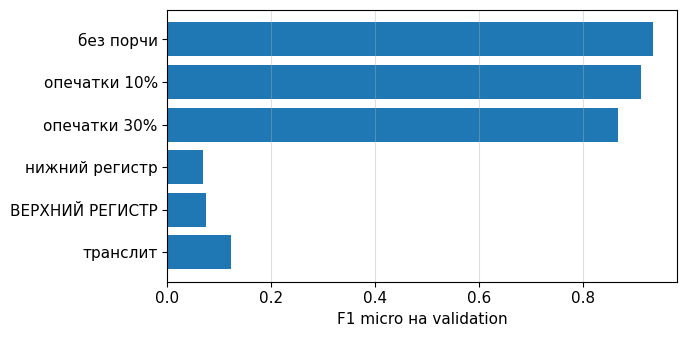

In [32]:
if '6.3' in BONUS_TASKS:
    TRANSLIT = {'а': 'a', 'б': 'b', 'в': 'v', 'г': 'g', 'д': 'd', 'е': 'e', 'ё': 'e', 'ж': 'zh', 'з': 'z',
                'и': 'i', 'й': 'y', 'к': 'k', 'л': 'l', 'м': 'm', 'н': 'n', 'о': 'o', 'п': 'p', 'р': 'r',
                'с': 's', 'т': 't', 'у': 'u', 'ф': 'f', 'х': 'kh', 'ц': 'ts', 'ч': 'ch', 'ш': 'sh',
                'щ': 'shch', 'ъ': '', 'ы': 'y', 'ь': '', 'э': 'e', 'ю': 'yu', 'я': 'ya'}

    def translit(word):
        out = []
        for ch in word:
            rep = TRANSLIT.get(ch.lower())
            if rep is None:
                out.append(ch)
            else:
                out.append(rep.capitalize() if ch != ch.lower() else rep)
        return ''.join(out) or word

    def add_typo(word, rng, rate):
        if len(word) < 4 or not word.isalpha() or rng.random() >= rate:
            return word
        i = rng.randrange(1, len(word) - 1)
        kind = rng.choice(['swap', 'drop', 'double'])
        if kind == 'swap':
            return word[:i] + word[i + 1] + word[i] + word[i + 2:]
        if kind == 'drop':
            return word[:i] + word[i + 1:]
        return word[:i] + word[i] + word[i:]

    def apply(tokens_list, fn):
        return [[fn(w) for w in words] for words in tokens_list]

    def typos(rate):
        def run(tokens_list):
            rng = random.Random(SEED)
            return apply(tokens_list, lambda w: add_typo(w, rng, rate))
        return run

    corruptions = {
        'без порчи': lambda ts: ts,
        'опечатки 10%': typos(0.1),
        'опечатки 30%': typos(0.3),
        'нижний регистр': lambda ts: apply(ts, str.lower),
        'ВЕРХНИЙ РЕГИСТР': lambda ts: apply(ts, str.upper),
        'транслит': lambda ts: apply(ts, translit),
    }

    def subwords_per_word(tokens_list):
        enc = tokenizer(tokens_list, is_split_into_words=True, truncation=False)
        n_sub = sum(len(ids) - 2 for ids in enc['input_ids'])
        return n_sub / sum(len(words) for words in tokens_list)

    shift = {}
    for name, fn in corruptions.items():
        corrupted = fn(val_tokens)
        scores = entity_scores(val_gold, predict_word_tags(model, corrupted))
        scores['subwords_per_word'] = subwords_per_word(corrupted)
        shift[name] = scores

    clean_f1 = shift['без порчи']['f1_micro']
    print(f'{"порча":<18}{"F1 micro":>10}{"падение":>10}{"precision":>11}{"recall":>9}{"сабвордов/слово":>17}')
    for name, s in shift.items():
        print(f'{name:<18}{s["f1_micro"]:>10.4f}{clean_f1 - s["f1_micro"]:>10.4f}{s["precision"]:>11.4f}'
              f'{s["recall"]:>9.4f}{s["subwords_per_word"]:>17.2f}')
    print('пример:', ' '.join(val_tokens[0][:12]), '->', ' '.join(corruptions['транслит'](val_tokens[:1])[0][:12]))

    plt.figure(figsize=(7, 3.5))
    plt.barh(list(shift)[::-1], [s['f1_micro'] for s in shift.values()][::-1])
    plt.xlabel('F1 micro на validation')
    plt.grid(True, axis='x', alpha=0.4)
    plt.tight_layout()
    plt.show()

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:**

Сильнее всего F1 роняют **регистр и транслит**, опечатки заметно меньше.

| порча | F1 micro | падение |
|---|---|---|
| без порчи | 0,9346 | 0 |
| опечатки 10% | 0,9118 | 0,0228 |
| опечатки 30% | 0,8684 | 0,0662 |
| нижний регистр | 0,0678 | 0,8668 |
| ВЕРХНИЙ РЕГИСТР | 0,0741 | 0,8605 |
| транслит | 0,1227 | 0,8120 |

- Модель в основном опирается на заглавную букву как признак имени собственного. В нижнем регистре recall 0,0376: она почти ничего не находит.
- Верхний регистр и транслит ещё и ломают токенизацию. Слова режутся на мелкие куски (3,46 и 2,47 сабвордов на слово против 1,14 без порчи), а таких кусков модель при обучении не видела. В верхнем регистре к тому же все слова заглавные, поэтому precision всего 0,05.
- Опечатки увеличивают число сабвордов умеренно (1,23 и 1,43), остальные буквы слова и контекст сохраняются, поэтому падение составляет лишь 2,3 и 6,6 пункта.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
%pip install -q onnx onnxruntime onnxscript

Note: you may need to restart the kernel to use updated packages.


In [34]:
if '6.4' in BONUS_TASKS:
    import onnxruntime as ort

    class LogitsOnly(torch.nn.Module):
        def __init__(self, inner):
            super().__init__()
            self.inner = inner

        def forward(self, input_ids, attention_mask):
            return self.inner(input_ids=input_ids, attention_mask=attention_mask).logits

    export_model = copy.deepcopy(model).cpu().eval()
    wrapper = LogitsOnly(export_model).eval()
    sample = tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt')
    sample_ids, sample_mask = sample['input_ids'], sample['attention_mask']

    ONNX_PATH = Path('runs/onnx/model.onnx')
    ONNX_PATH.parent.mkdir(parents=True, exist_ok=True)
    export_args = dict(input_names=['input_ids', 'attention_mask'], output_names=['logits'])
    try:
        torch.onnx.export(wrapper, (sample_ids, sample_mask), ONNX_PATH.as_posix(), opset_version=17, dynamo=False,
                          dynamic_axes={'input_ids': {0: 'batch', 1: 'seq'}, 'attention_mask': {0: 'batch', 1: 'seq'},
                                        'logits': {0: 'batch', 1: 'seq'}}, **export_args)
    except Exception as err:
        print('старый экспорт не прошел:', type(err).__name__, str(err)[:200])
        dyn = torch.export.Dim.DYNAMIC
        torch.onnx.export(wrapper, (sample_ids, sample_mask), ONNX_PATH.as_posix(), dynamo=True,
                          dynamic_shapes={'input_ids': {0: dyn, 1: dyn}, 'attention_mask': {0: dyn, 1: dyn}},
                          **export_args)
    print(f'ONNX: {ONNX_PATH.stat().st_size / 2**20:.1f} МБ')

    session = ort.InferenceSession(ONNX_PATH.as_posix(), providers=['CPUExecutionProvider'])
    feeds = {'input_ids': sample_ids.numpy().astype(np.int64), 'attention_mask': sample_mask.numpy().astype(np.int64)}

    with torch.inference_mode():
        torch_logits = wrapper(sample_ids, sample_mask).numpy()
    onnx_logits = session.run(['logits'], feeds)[0]
    print('макс. расхождение логитов:', float(np.abs(torch_logits - onnx_logits).max()))

    def predict_onnx(sess, tokens_list, batch_size=64):
        all_tags = []
        for start in range(0, len(tokens_list), batch_size):
            batch = [list(ws) for ws in tokens_list[start:start + batch_size]]
            enc = tokenizer(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH,
                            padding=True, return_tensors='np')
            logits = sess.run(['logits'], {'input_ids': enc['input_ids'].astype(np.int64),
                                           'attention_mask': enc['attention_mask'].astype(np.int64)})[0]
            best = logits.argmax(-1)
            for i, words in enumerate(batch):
                tags, seen = ['O'] * len(words), set()
                for pos, w in enumerate(enc.word_ids(i)):
                    if w is None or w in seen:
                        continue
                    seen.add(w)
                    tags[w] = id2label[int(best[i, pos])]
                all_tags.append(tags)
        return all_tags

    def bench(fn, warmup=3, runs=20):
        for _ in range(warmup):
            fn()
        times = []
        for _ in range(runs):
            start = time.perf_counter()
            fn()
            times.append(time.perf_counter() - start)
        return 1000 * float(np.mean(times)), 1000 * float(np.std(times))

    def torch_cpu():
        with torch.inference_mode():
            wrapper(sample_ids, sample_mask)

    latency = {'PyTorch CPU': bench(torch_cpu), 'ONNX Runtime CPU': bench(lambda: session.run(['logits'], feeds))}

    if device.type == 'cuda':
        gpu_model = LogitsOnly(model.to(device).eval())
        gpu_ids, gpu_mask = sample_ids.to(device), sample_mask.to(device)

        def torch_gpu():
            with torch.inference_mode():
                gpu_model(gpu_ids, gpu_mask)
            torch.cuda.synchronize()

        latency[f'PyTorch {DEVICE_NAME}'] = bench(torch_gpu)

    print(f'\nбатч {tuple(sample_ids.shape)}')
    for name, (mean_ms, std_ms) in latency.items():
        print(f'{name:<28}{mean_ms:>9.1f} ± {std_ms:.1f} мс')
    print(f'ускорение ONNX Runtime относительно PyTorch на CPU: '
          f'{latency["PyTorch CPU"][0] / latency["ONNX Runtime CPU"][0]:.2f}x')

    onnx_pred = predict_onnx(session, val_tokens)
    onnx_scores = entity_scores(val_gold, onnx_pred)
    torch_scores = entity_scores(val_gold, val_pred)
    print(f'\nF1 micro на validation: PyTorch {torch_scores["f1_micro"]:.4f}, ONNX {onnx_scores["f1_micro"]:.4f}, '
          f'разница {onnx_scores["f1_micro"] - torch_scores["f1_micro"]:+.4f}')

/tmp/ipykernel_22/163900940.py:21: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(wrapper, (sample_ids, sample_mask), ONNX_PATH.as_posix(), opset_version=17, dynamo=False,
/usr/local/lib/python3.13/dist-packages/transformers/masking_utils.py:208: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if (padding_length := kv_length + kv_offset - attention_mask.shape[-1]) > 0:
/usr/local/lib/python3.13/dist-packages/transformers/int

ONNX: 111.1 МБ
макс. расхождение логитов: 3.814697265625e-06

батч (32, 64)
PyTorch CPU                      61.0 ± 6.5 мс
ONNX Runtime CPU                111.4 ± 10.6 мс
PyTorch Tesla T4                  5.2 ± 0.1 мс
ускорение ONNX Runtime относительно PyTorch на CPU: 0.55x

F1 micro на validation: PyTorch 0.9346, ONNX 0.9346, разница +0.0000


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:**

Замер на батче 32 × 64 (прогрев 3 запуска, среднее по 20):

| вариант | задержка |
|---|---|
| PyTorch, CPU | 61,0 ± 6,5 мс |
| ONNX Runtime, CPU | 111,4 ± 10,6 мс |
| PyTorch, Tesla T4 | 5,2 ± 0,1 мс |

На CPU ONNX Runtime оказался **не быстрее** PyTorch: ускорение 0,55x, то есть замедление почти вдвое. GPU Tesla T4 считает тот же батч примерно в 12 раз быстрее CPU.

Метрика не изменилась: F1 на validation 0,9346 и в PyTorch, и в ONNX (разница 0,0000), максимальное расхождение логитов около 4·10⁻⁶. Это ожидаемо: граф тот же, различается только порядок вычислений с плавающей точкой.

У `rubert-tiny2` почти все параметры (92%, 26,8 млн из 29,1 млн) лежат в таблице эмбеддингов, а это просто выбор строк, который не ускоряется оптимизациями графа. Сам энкодер из трёх слоёв с hidden 312 крошечный, и его вычисления быстро выполняются и в PyTorch. Выигрыш от ONNX Runtime (слияние операций, оптимизация графа) заметен на глубоких моделях, где доминируют матричные умножения, а здесь накладные расходы на вызов и конвертацию легко его съедают. Разброс замеров на CPU заметный (±6,5 и ±10,6 мс), но разница между вариантами намного больше него.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

агрегация   порог  val F1 при 0  val F1 при пороге  прирост  test F1 при 0  test F1 при пороге
mean         0.81        0.9346             0.9392  +0.0046         0.9354              0.9364
min          0.77        0.9346             0.9386  +0.0040         0.9354              0.9385
для сверки: F1 micro на validation из 4.2 = 0.9346


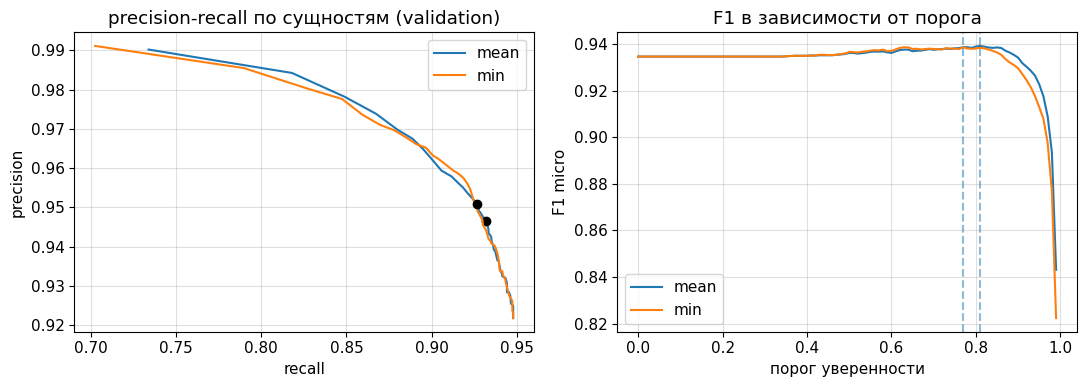

In [35]:
if '6.5' in BONUS_TASKS:
    def span_table(tokens_list, gold_tags, agg):
        tags_list, probs_list = predict_word_tags(model, tokens_list, return_probs=True)
        confs, correct, n_gold = [], [], 0
        for tags, probs, gold_seq in zip(tags_list, probs_list, gold_tags):
            gold_spans = set(bio_to_spans(gold_seq))
            n_gold += len(gold_spans)
            for span in bio_to_spans(tags):
                confs.append(agg(probs[span[0]:span[1]]))
                correct.append(span in gold_spans)
        return np.array(confs), np.array(correct), n_gold

    def prf(confs, correct, n_gold, threshold):
        keep = confs >= threshold
        n_pred, tp = int(keep.sum()), int((keep & correct).sum())
        precision = tp / n_pred if n_pred else 0.0
        recall = tp / n_gold if n_gold else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        return precision, recall, f1

    thresholds = np.linspace(0.0, 0.99, 100)
    aggregations = {'mean': np.mean, 'min': np.min}
    sweep = {}
    for agg_name, agg in aggregations.items():
        val_table = span_table(val_tokens, val_gold, agg)
        curve = np.array([prf(*val_table, thr) for thr in thresholds])
        best = int(curve[:, 2].argmax())
        test_table = span_table(test_tokens, test_gold, agg)
        sweep[agg_name] = dict(curve=curve, best=best,
                               test_at_0=prf(*test_table, 0.0), test_at_best=prf(*test_table, thresholds[best]))

    print(f'{"агрегация":<10}{"порог":>7}{"val F1 при 0":>14}{"val F1 при пороге":>19}{"прирост":>9}'
          f'{"test F1 при 0":>15}{"test F1 при пороге":>20}')
    for agg_name, r in sweep.items():
        f1_zero, f1_best = r['curve'][0, 2], r['curve'][r['best'], 2]
        print(f'{agg_name:<10}{thresholds[r["best"]]:>7.2f}{f1_zero:>14.4f}{f1_best:>19.4f}{f1_best - f1_zero:>+9.4f}'
              f'{r["test_at_0"][2]:>15.4f}{r["test_at_best"][2]:>20.4f}')
    print(f'для сверки: F1 micro на validation из 4.2 = {entity_scores(val_gold, val_pred)["f1_micro"]:.4f}')

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for agg_name, r in sweep.items():
        axes[0].plot(r['curve'][:, 1], r['curve'][:, 0], label=agg_name)
        axes[0].plot(r['curve'][r['best'], 1], r['curve'][r['best'], 0], 'ko')
        axes[1].plot(thresholds, r['curve'][:, 2], label=agg_name)
        axes[1].axvline(thresholds[r['best']], ls='--', alpha=0.5)
    axes[0].set_xlabel('recall')
    axes[0].set_ylabel('precision')
    axes[0].set_title('precision-recall по сущностям (validation)')
    axes[1].set_xlabel('порог уверенности')
    axes[1].set_ylabel('F1 micro')
    axes[1].set_title('F1 в зависимости от порога')
    for ax in axes:
        ax.grid(True, alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:**

| агрегация | лучший порог | F1 при 0 (validation) | F1 при пороге (validation) | прирост | F1 при 0 (test) | F1 при пороге (test) |
|---|---|---|---|---|---|---|
| средняя | 0,81 | 0,9346 | 0,9392 | +0,0046 | 0,9354 | 0,9364 |
| минимальная | 0,77 | 0,9346 | 0,9386 | +0,0040 | 0,9354 | 0,9385 |

На validation, где порог подбирался, выигрыш около 0,004-0,005. На test он только +0,0010 (средняя) и +0,0031 (минимальная). Для средней это сопоставимо с разбросом между запусками модели, так что говорить о реальном улучшении нельзя: порог в основном подстроился под validation. У минимальной на test выигрыш чуть больше, но он тоже мал.

Средняя уверенность усредняет вероятности слов спана, поэтому одно неуверенное слово в длинном спане может потеряться. Минимальная реагирует на самое слабое слово и строже к многословным спанам; поэтому лучший порог у неё ниже (0,77 против 0,81). Для спанов из одного слова они совпадают.

Порог не может поднять recall, потому что он только отбрасывает уже предсказанные спаны и ничего не добавляет. Число найденных верных спанов может только уменьшиться или остаться прежним, а F1 растёт за счёт precision.